# SPY Decision Tree: Will SPY Close Up Today?

**Course:** CSIS 3360 – Fundamentals of Data Analytics
**Team member:** Tuấn
**Model:** Decision Tree (classification)

## Goal

The stock market opens at 9:30 a.m. New York time. At that point we already know today's opening price and all the
data from the days before. We want to see if that is enough to predict whether SPY will close above yesterday's close.

- 1 = UP (today's close is higher than yesterday's close)
- 0 = DOWN (the same or lower)

We only use information that exists at 9:30. Today's High, Low, Close and Volume are not known yet, so they are not
used as features.

The same tree is built by hand in Excel (`Excel/Classification_DecisionTree_OpenGap_SPY.xlsx`). The numbers in this
notebook match the workbook.

## Steps

1. Libraries
2. Load the data
3. First look at the data
4. Data quality checks
5. Features and target
6. Exploring the data
7. Train, validation and test split
8. Building the tree
9. Results on 2023 (validation) and 2024–2025 (test)
10. Extra checks
11. Save output files
12. Conclusion

## 1. Libraries

In [1]:
# libraries for the data, the charts and the decision tree
from pathlib import Path
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.metrics import confusion_matrix

# same colours in every chart: blue = UP, orange = DOWN
UP_COLOR, DOWN_COLOR = "#2a78d6", "#eb6834"
DARK, GREY, INK = "#52514e", "#898781", "#0b0b0b"

# simple chart style
plt.rcParams.update({
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": DARK, "xtick.color": DARK, "ytick.color": DARK,
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6, "axes.axisbelow": True,
})

# charts and csv files go into the outputs folder
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

def save(fig, name):
    fig.savefig(OUTPUT_DIR / name, dpi=150, bbox_inches="tight")

## 2. Load the Data

Source: Stooq, daily SPY prices (https://stooq.com/q/d/?s=spy.us), 2010-01-04 to 2025-12-31.
The original file `spy_us_d.csv` is not changed. All the work below is done on a copy.

In [2]:
# load the csv (it is in the main project folder, one level up from this notebook)
candidate_paths = [Path("..") / "spy_us_d.csv", Path("spy_us_d.csv")]
DATA_PATH = next((p for p in candidate_paths if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("spy_us_d.csv not found")

raw = pd.read_csv(DATA_PATH)
raw.head()

,Date,Open,High,Low,Close,Volume
0,2010-01-04,86.7050,87.4819,86.0150,87.4353,154164947
1,2010-01-05,87.3929,87.6975,87.0771,87.6670,144619532
2,2010-01-06,87.5854,87.9358,87.5089,87.7137,150444938
3,2010-01-07,87.5712,88.2019,87.3358,88.1023,169908131
4,2010-01-08,87.8564,88.4334,87.6859,88.3952,163831612


## 3. First Look at the Data

In [3]:
# size, columns and data types
print("Rows and columns:", raw.shape)
print(raw.dtypes.to_string())

# Date is read as text, so turn it into a real date and sort from oldest to newest
df = raw.copy()
df["Date"] = pd.to_datetime(df["Date"])
df = df.sort_values("Date").reset_index(drop=True)
print("\nFrom", df["Date"].min().date(), "to", df["Date"].max().date(), "-", len(df), "trading days")

Rows and columns: (4023, 6)
Date          str
Open      float64
High      float64
Low       float64
Close     float64
Volume      int64

From 2010-01-04 to 2025-12-31 - 4023 trading days


## 4. Data Quality Checks

### 4.1 Basic checks

In [4]:
# look for missing values, duplicate dates, impossible prices and weekend dates
# a normal day must have Low <= Open, Close <= High
prices = df[["Open", "High", "Low", "Close"]]
checks = {
    "Missing values": df.isna().sum().sum(),
    "Duplicate dates": df["Date"].duplicated().sum(),
    "Prices <= 0": (prices <= 0).sum().sum(),
    "Volume <= 0": (df["Volume"] <= 0).sum(),
    "High below Low": (df["High"] < df["Low"]).sum(),
    "High below Open or Close": (df["High"] < prices[["Open", "Close"]].max(axis=1)).sum(),
    "Low above Open or Close": (df["Low"] > prices[["Open", "Close"]].min(axis=1)).sum(),
    "Weekend dates": (df["Date"].dt.dayofweek >= 5).sum(),
}
pd.Series(checks, name="Problems found").astype(int).to_frame()

,Problems found
Missing values,0
Duplicate dates,0
Prices <= 0,0
Volume <= 0,0
High below Low,0
High below Open or Close,0
Low above Open or Close,0
Weekend dates,0


No problems found in any of these checks.

### 4.2 Missing trading days

In [5]:
# count the trading days in each year and compare with the official NYSE calendar
nyse_trading_days = {2010: 252, 2011: 252, 2012: 250, 2013: 252, 2014: 252, 2015: 252, 2016: 252, 2017: 251,
                     2018: 251, 2019: 252, 2020: 253, 2021: 252, 2022: 251, 2023: 250, 2024: 252, 2025: 250}
per_year = df.groupby(df["Date"].dt.year).size().rename("Days in data").to_frame()
per_year["NYSE calendar"] = per_year.index.map(nyse_trading_days)
per_year["Missing"] = per_year["NYSE calendar"] - per_year["Days in data"]
per_year.index.name = "Year"
display(per_year.T)

# 2011 is one day short, so list the weekdays of that week that are not in the file
week = pd.bdate_range("2011-02-14", "2011-02-23")
print("Weekdays not in the file:", [d.strftime("%a %Y-%m-%d") for d in week if d not in set(df["Date"])])

# any jump of more than 4 calendar days between two rows (normal is 1, or 3-4 over a weekend)
days_between = df["Date"].diff().dt.days
print("Jumps longer than 4 days end on:", df.loc[days_between > 4, "Date"].dt.date.tolist())

Year,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
Days in data,252,251,250,252,252,252,252,251,251,252,253,252,251,250,252,250
NYSE calendar,252,252,250,252,252,252,252,251,251,252,253,252,251,250,252,250
Missing,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0


Weekdays not in the file: ['Thu 2011-02-17', 'Mon 2011-02-21']
Jumps longer than 4 days end on: [datetime.date(2012, 10, 31)]


Every year matches the NYSE calendar except 2011, which is missing **Thursday 17 February 2011**. (Monday 21 February
was Presidents' Day, so the market was closed that day.) The jump from 26 to 31 October 2012 is not missing data:
the market was closed for Hurricane Sandy.

We keep the data as it is. The missing day only affects the next row (18 February 2011), because its gap is measured
from the close two days earlier. In section 8.2 we check that the tree comes out the same without that row.

### 4.3 Outliers (IQR rule)

We use the IQR rule from class on four variables: the gap, the daily return, the intraday range and the volume.
Anything below Q1 − 1.5 × IQR or above Q3 + 1.5 × IQR is flagged. A flag does not mean the value is wrong, so we
look at the flagged days before deciding anything.

In [6]:
# flag outliers with the IQR rule (we only flag them here, nothing is deleted)
check = pd.DataFrame({
    "Date": df["Date"],
    "Gap (%)": (df["Open"] / df["Close"].shift(1) - 1) * 100,
    "Daily Return (%)": df["Close"].pct_change() * 100,
    "Intraday Range (%)": (df["High"] - df["Low"]) / df["Close"] * 100,
    "Volume (millions)": df["Volume"] / 1_000_000,
})
CHECK_COLS = ["Gap (%)", "Daily Return (%)", "Intraday Range (%)", "Volume (millions)"]

def iqr_bounds(series):
    q1, q3 = series.quantile(0.25), series.quantile(0.75)
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

rows = []
for col in CHECK_COLS:
    values = check[col].dropna()
    low, high = iqr_bounds(values)
    flagged = (values < low) | (values > high)
    rows.append({"Variable": col, "Lower bound": low, "Upper bound": high,
                 "Flagged days": int(flagged.sum()), "Flagged (%)": flagged.mean() * 100})
outlier_summary = pd.DataFrame(rows).round(2)
outlier_summary

,Variable,Lower bound,Upper bound,Flagged days,Flagged (%)
0,Gap (%),-1.07,1.18,291,7.24
1,Daily Return (%),-1.79,2.00,267,6.64
2,Intraday Range (%),-0.51,2.48,227,5.64
3,Volume (millions),-59.03,285.70,234,5.82


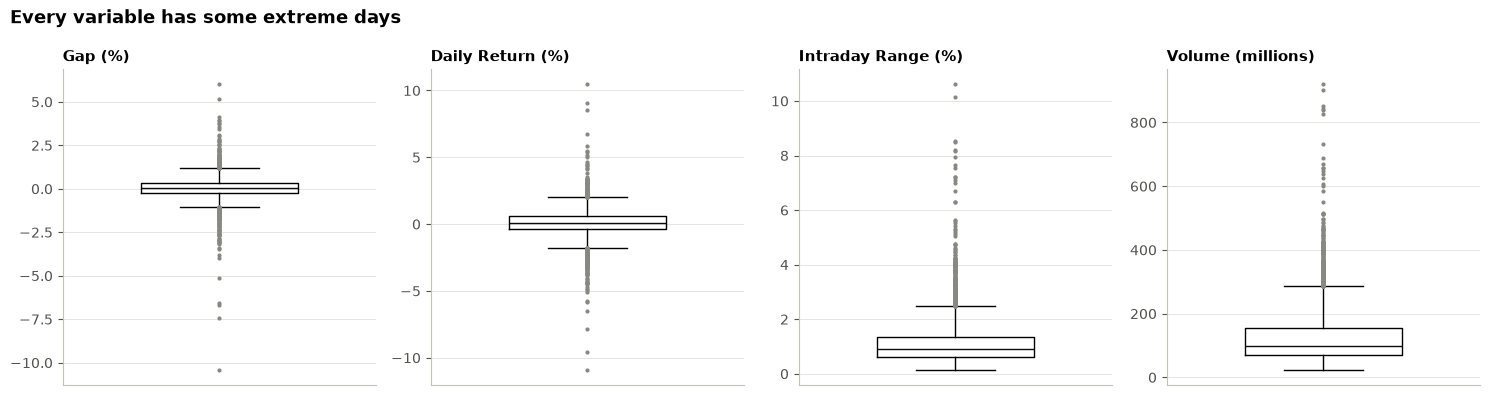

In [7]:
# boxplots: the dots outside the whiskers are the flagged days
fig, axes = plt.subplots(1, 4, figsize=(15, 4))
for ax, col in zip(axes, CHECK_COLS):
    ax.boxplot(check[col].dropna(), whis=1.5, widths=0.5, medianprops={"color": INK},
               flierprops={"marker": "o", "markersize": 3, "markerfacecolor": GREY, "markeredgecolor": "none"})
    ax.set_title(col, fontsize=11)
    ax.set_xticks([])
fig.suptitle("Every variable has some extreme days", x=0.01, ha="left", fontweight="bold", fontsize=13)
fig.tight_layout()
save(fig, "open_gap_outlier_boxplots.png")
plt.show()

In [8]:
# the 10 biggest gaps (up or down), with the market event on that day
events = {"2020-03-16": "COVID-19 crash", "2020-03-09": "COVID-19 crash", "2020-03-12": "COVID-19 crash",
          "2020-03-18": "COVID-19 crash", "2020-03-13": "COVID-19 crash", "2020-03-24": "COVID-19 crash",
          "2015-08-24": "August 2015 global sell-off", "2010-05-10": "European debt rescue package",
          "2024-08-05": "August 2024 global sell-off", "2020-11-09": "First COVID-19 vaccine results"}
biggest = check.assign(size=check["Gap (%)"].abs()).nlargest(10, "size").drop(columns="size")
biggest["Event"] = biggest["Date"].dt.strftime("%Y-%m-%d").map(events)
biggest.round({c: 2 for c in CHECK_COLS})

,Date,Gap (%),Daily Return (%),Intraday Range (%),Volume (millions),Event
2565,2020-03-16,-10.44,-10.95,8.15,321.60,COVID-19 crash
2560,2020-03-09,-7.45,-7.82,3.91,334.77,COVID-19 crash
2563,2020-03-12,-6.69,-9.56,7.65,424.36,COVID-19 crash
2567,2020-03-18,-6.55,-5.07,8.48,354.44,COVID-19 crash
2564,2020-03-13,6.04,8.55,8.52,356.57,COVID-19 crash
2571,2020-03-24,5.14,9.06,4.23,253.30,COVID-19 crash
1418,2015-08-24,-5.12,-4.08,7.94,599.81,August 2015 global sell-off
87,2010-05-10,4.12,4.42,1.47,513.47,European debt rescue package
3669,2024-08-05,-3.99,-2.91,2.57,147.65,August 2024 global sell-off
2731,2020-11-09,3.95,1.26,2.91,183.78,First COVID-19 vaccine results


In [9]:
# the one value we could not explain: very high volume on 28 Jan 2015, shown with the days around it
around = check[(check["Date"] >= "2015-01-26") & (check["Date"] <= "2015-01-30")]
around[["Date", "Daily Return (%)", "Volume (millions)"]].round({"Daily Return (%)": 2, "Volume (millions)": 1})

,Date,Daily Return (%),Volume (millions)
1272,2015-01-26,0.23,109.6
1273,2015-01-27,-1.32,159.9
1274,2015-01-28,-1.29,731.0
1275,2015-01-29,0.92,207.1
1276,2015-01-30,-1.25,236.0


Between 5.6% and 7.2% of the days are flagged for each variable. The biggest gaps all line up with real market events (the COVID-19
crash in March 2020, the August 2015 sell-off, the August 2024 sell-off), so they are real data and we keep them.
Removing crash days would make the model look better than it really is.

One value looks strange: on 28 January 2015 the volume is about 731 million shares on a normal day, around 4 times the
days next to it. Nguyên's regression notebook flagged the same day. We keep it, and it does not matter for this model
because the tree never uses volume (section 8.2).

Outliers are also less of a problem for a decision tree than for a regression. A tree only asks "is this value above
or below the cut-off?", so a −10% gap just ends up in the "big gap down" group. It cannot pull the cut-off towards it.

### 4.4 Cleaning summary

| Check | Result | What we did |
|---|---|---|
| Missing values, duplicates, bad prices, weekend dates | None | Nothing needed |
| Missing trading days | 1 day (2011-02-17) | Kept, checked in 8.2 |
| Extreme gaps, returns and ranges | Real market events | Kept |
| Volume on 2015-01-28 | Looks wrong, no event found | Kept, the tree does not use volume |

No rows are removed in cleaning. The only rows we drop later are the first 21 days, which do not have enough history
for the 20-day features.

## 5. Features and Target

### 5.1 Create the features

These are the same formulas as the Prices tab in Excel. `shift(1)` takes the value from the row above (yesterday) and
`rolling(20)` looks at the last 20 rows.

In [10]:
# the 5 features and the target
FEATURES = ["Gap", "Prev Return", "Prev Range", "Prev Volatility 20D", "Prev Volume Ratio"]
TARGET = "Close Up"

def make_features(prices):
    out = prices.copy()
    out["Prev Close"] = out["Close"].shift(1)
    out["Day Return"] = out["Close"] / out["Prev Close"] - 1                  # helper only, known at 4 pm
    out["Gap"] = out["Open"] / out["Prev Close"] - 1                          # today's open vs yesterday's close
    out["Prev Return"] = out["Day Return"].shift(1)                           # yesterday's return
    out["Prev Range"] = ((out["High"] - out["Low"]) / out["Close"]).shift(1)  # yesterday's high-low range
    out["Prev Volatility 20D"] = out["Day Return"].rolling(20).std().shift(1) # std of the last 20 returns
    out["Prev Volume Ratio"] = (out["Volume"] / out["Volume"].rolling(20).mean()).shift(1)   # yesterday's volume vs its 20-day average
    out[TARGET] = (out["Close"] > out["Prev Close"]).astype(int)              # 1 = UP, 0 = DOWN
    return out

data = make_features(df)
data[["Date", "Open", "Close"] + FEATURES + [TARGET]].iloc[21:26]

,Date,Open,Close,Gap,Prev Return,Prev Range,Prev Volatility 20D,Prev Volume Ratio,Close Up
21,2010-02-03,84.7668,84.7352,-0.004708,0.012090,0.015721,0.010619,1.083765,0
22,2010-02-04,84.0815,82.1271,-0.007715,-0.005079,0.008935,0.010610,0.852295,0
23,2010-02-05,82.2170,82.2889,0.001095,-0.030779,0.024531,0.012426,1.661481,1
24,2010-02-08,82.3578,81.6993,0.000837,0.001970,0.021610,0.012359,2.120013,0
25,2010-02-09,82.6525,82.7215,0.011667,-0.007165,0.014375,0.012283,0.943025,1


In [11]:
# check one day by hand (same example as the Excel Definition tab):
# 2 June 2023, open 413.18 / yesterday's close 410.57 - 1 = +0.64%, and it closed higher, so Close Up = 1
data.loc[data["Date"] == "2023-06-02", ["Date", "Prev Close", "Open", "Gap", "Close", TARGET]]

,Date,Prev Close,Open,Gap,Close,Close Up
3375,2023-06-02,410.574,413.182,0.006352,416.51,1


### 5.2 What the features mean

| Feature | What it is | Why we tried it |
|---|---|---|
| Gap | How far today opened above or below yesterday's close | News from overnight is already in the opening price |
| Prev Return | Yesterday's close-to-close change | A strong day might be followed by another one, or by a bounce back |
| Prev Range | Yesterday's high minus low, as % of the close | How nervous the market was yesterday |
| Prev Volatility 20D | Standard deviation of the last 20 daily returns | Calm and stressful periods might behave differently |
| Prev Volume Ratio | Yesterday's volume compared to its 20-day average | Very busy days often come with news |

All five are known at 9:30. We use percentages and ratios instead of prices because SPY went from about \$87 to
\$682 over these years, so a cut-off like "price below \$150" would mean nothing in 2023.

### 5.3 Leakage check

To make sure no feature uses information from after 9:30, we pick 50 random days, delete everything after each day,
hide that day's High, Low, Close and Volume, and build the features again. They should come out exactly the same.

In [12]:
# leakage check: rebuild the features for 50 random days using only what is known at 9:30
rng = np.random.default_rng(0)
sample_days = rng.choice(np.arange(21, len(df)), size=50, replace=False)

changed = 0
for i in sample_days:
    at_930 = df.loc[:i].copy()                                   # no later days
    at_930.loc[i, ["High", "Low", "Close", "Volume"]] = np.nan   # not known yet at 9:30
    again = make_features(at_930)
    if not np.allclose(again.loc[i, FEATURES].astype(float), data.loc[i, FEATURES].astype(float), rtol=0, atol=1e-15):
        changed += 1

print("Days where a feature changed:", changed, "of", len(sample_days))

Days where a feature changed: 0 of 50


None of the features changed, so they only use information available at the open.

### 5.4 Remove the warm-up days

In [13]:
# drop the first 21 days (not enough history for the 20-day features) and label each day's set
usable = data.dropna(subset=FEATURES).copy()
year = usable["Date"].dt.year
usable["Set"] = np.select([year <= 2022, year == 2023], ["Train", "Validation"], default="Test")

print(len(data) - len(usable), "warm-up days dropped,", len(usable), "days left, starting", usable["Date"].min().date())

21 warm-up days dropped, 4002 days left, starting 2010-02-03


## 6. Exploring the Data

### 6.1 SPY over time

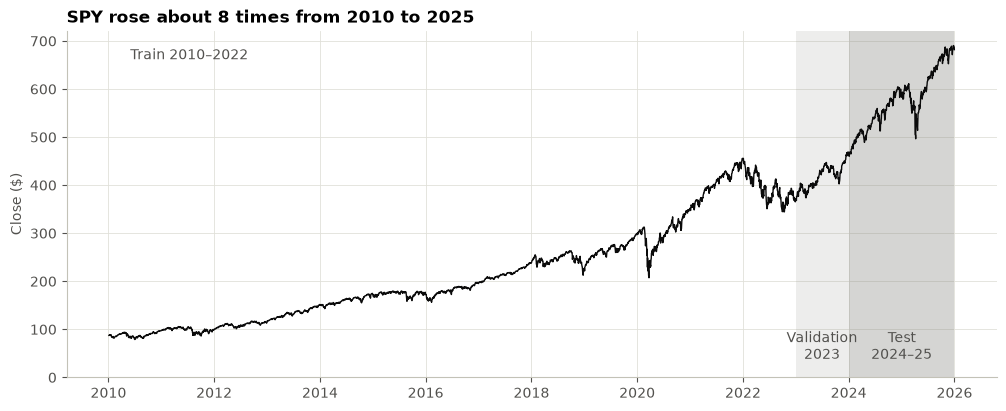

In [14]:
# closing price with the three periods we use
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(df["Date"], df["Close"], color=INK, linewidth=1)
ax.axvspan(pd.Timestamp("2023-01-01"), pd.Timestamp("2023-12-31"), color=GREY, alpha=0.15, lw=0)
ax.axvspan(pd.Timestamp("2024-01-01"), df["Date"].max(), color=GREY, alpha=0.35, lw=0)
top = ax.get_xaxis_transform()
ax.text(pd.Timestamp("2010-06-01"), 0.95, "Train 2010–2022", transform=top, va="top", color=DARK)
ax.text(pd.Timestamp("2023-07-01"), 0.04, "Validation\n2023", transform=top, ha="center", va="bottom", color=DARK)
ax.text(pd.Timestamp("2025-01-01"), 0.04, "Test\n2024–25", transform=top, ha="center", va="bottom", color=DARK)
ax.set_ylim(0, None)
ax.set_ylabel("Close ($)")
ax.set_title("SPY rose about 8 times from 2010 to 2025")
save(fig, "open_gap_price_and_periods.png")
plt.show()

### 6.2 Opening gap vs closing up

We group the training days by the size of their gap and check how many of them closed up.

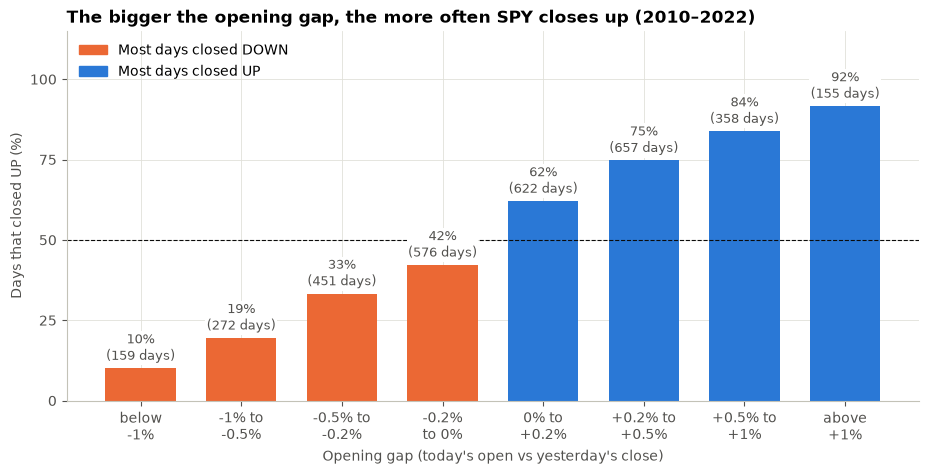

In [15]:
# share of UP days for each gap size (training days only)
train_days = usable[usable["Set"] == "Train"]
bins = [-np.inf, -0.01, -0.005, -0.002, 0, 0.002, 0.005, 0.01, np.inf]
labels = ["below\n-1%", "-1% to\n-0.5%", "-0.5% to\n-0.2%", "-0.2%\nto 0%", "0% to\n+0.2%", "+0.2% to\n+0.5%",
          "+0.5% to\n+1%", "above\n+1%"]
gap_groups = (train_days.assign(group=pd.cut(train_days["Gap"], bins=bins, labels=labels))
                        .groupby("group", observed=True)[TARGET].agg(days="count", share_up="mean"))
gap_groups["share_up"] *= 100

fig, ax = plt.subplots(figsize=(11, 4.8))
colors = [UP_COLOR if v > 50 else DOWN_COLOR for v in gap_groups["share_up"]]
bars = ax.bar(gap_groups.index.astype(str), gap_groups["share_up"], color=colors, width=0.7)
ax.axhline(50, color=INK, lw=0.8, ls="--")
texts = ax.bar_label(bars, labels=[f"{v:.0f}%\n({n:,} days)" for v, n in zip(gap_groups["share_up"], gap_groups["days"])],
                     padding=3, color=DARK, fontsize=9)
for t in texts:
    t.set_bbox({"facecolor": "white", "edgecolor": "none", "pad": 1})
ax.set_ylim(0, 115)
ax.set_yticks(range(0, 101, 25))
ax.set_xlabel("Opening gap (today's open vs yesterday's close)")
ax.set_ylabel("Days that closed UP (%)")
ax.legend(handles=[Patch(color=DOWN_COLOR, label="Most days closed DOWN"), Patch(color=UP_COLOR, label="Most days closed UP")],
          loc="upper left", frameon=False)
ax.set_title("The bigger the opening gap, the more often SPY closes up (2010–2022)")
save(fig, "open_gap_share_up_by_gap.png")
plt.show()

This is the main pattern in the data. After a gap down of more than 1%, only 10% of days closed up. After a gap up of
more than 1%, 92% did. The switch from mostly DOWN to mostly UP happens close to a gap of 0%.

### 6.3 Correlation

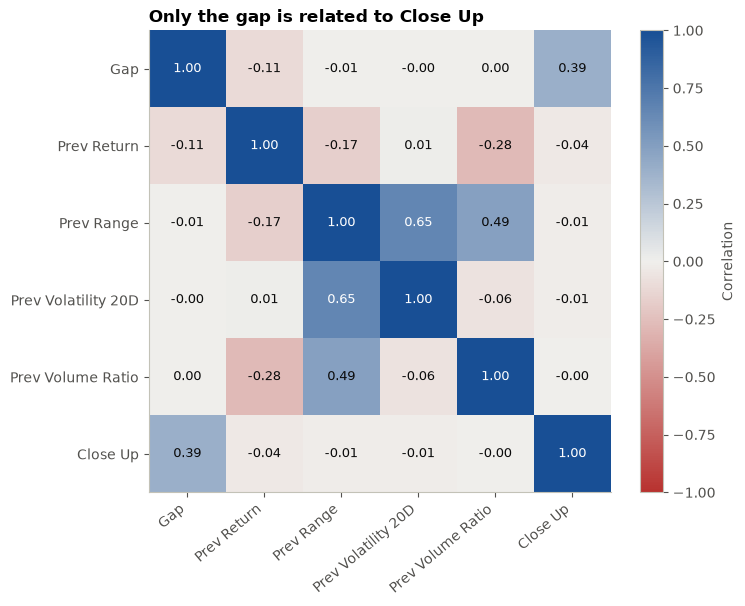

In [16]:
# correlation between the features and the target (training days only)
corr = train_days[FEATURES + [TARGET]].corr()
red_grey_blue = LinearSegmentedColormap.from_list("rgb", ["#b8322f", "#f0efec", "#184f95"])

fig, ax = plt.subplots(figsize=(7.5, 6))
image = ax.imshow(corr, cmap=red_grey_blue, vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=40, ha="right")
ax.set_yticks(range(len(corr)), corr.index)
for i in range(len(corr)):
    for j in range(len(corr)):
        v = corr.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=9, color="white" if abs(v) > 0.6 else INK)
ax.grid(False)
fig.colorbar(image, ax=ax, label="Correlation")
ax.set_title("Only the gap is related to Close Up")
save(fig, "open_gap_correlation.png")
plt.show()

Gap has a correlation of 0.39 with Close Up. The other four features are all below 0.05, so on their own they say
almost nothing about today's close. Prev Range and Prev Volatility 20D are related to each other (0.65), which makes
sense because both measure how jumpy the market is. For a tree this is fine, since it just picks the best single
question at each step.

## 7. Train, Validation and Test Split

The split is by date, not random, because we can't learn from the future:

- Train 2010–2022: the tree learns from these days
- Validation 2023: used to check the tree
- Test 2024–2025: used once, after the tree was final

The baseline is to always guess UP, because most training days closed up.

In [17]:
# split by date and show how often each period closed up (= the always-UP baseline)
train = usable[usable["Set"] == "Train"]
valid = usable[usable["Set"] == "Validation"]
test = usable[usable["Set"] == "Test"]

pd.DataFrame({
    "Dates": ["2010-02-03 to 2022-12-30", "2023", "2024-2025"],
    "Days": [len(train), len(valid), len(test)],
    "Share UP (always-UP accuracy)": [f"{s[TARGET].mean():.1%}" for s in (train, valid, test)],
}, index=["Train", "Validation", "Test"])

,Dates,Days,Share UP (always-UP accuracy)
Train,2010-02-03 to 2022-12-30,3250,54.8%
Validation,2023,250,56.0%
Test,2024-2025,502,58.0%


## 8. Building the Tree

### 8.1 The first question by hand (Excel: Entropy and Cut Off tabs)

This is the ID3 method from class. For each feature we try every cut-off halfway between two values, skip cut-offs
that leave fewer than 50 days on one side, and keep the one with the highest information gain.

In [18]:
# entropy and information gain, the same formulas as the Excel Entropy tab
def entropy(up, down):
    total = up + down
    result = 0.0
    for count in (up, down):
        if count > 0:
            p = count / total
            result -= p * np.log2(p)
    return result

def info_gain(x, y, cut):
    yes, no = y[x <= cut], y[x > cut]
    n = len(y)
    before = entropy(y.sum(), n - y.sum())
    after = len(yes) / n * entropy(yes.sum(), len(yes) - yes.sum()) + len(no) / n * entropy(no.sum(), len(no) - no.sum())
    return before - after

# try every halfway cut-off and keep the best one (Excel Cut Off tab)
def best_cut(x, y, min_leaf=50):
    x, y = np.asarray(x), np.asarray(y)
    values = np.unique(x)
    best, best_gain = None, -1.0
    for low, high in zip(values[:-1], values[1:]):
        cut = (low + high) / 2
        n_yes = (x <= cut).sum()
        if n_yes < min_leaf or len(x) - n_yes < min_leaf:
            continue
        gain = info_gain(x, y, cut)
        if gain > best_gain:
            best, best_gain = cut, gain
    return best, best_gain

up = int(train[TARGET].sum())
print(f"Training days: {len(train)}, UP: {up}, DOWN: {len(train) - up}, entropy: {entropy(up, len(train) - up):.4f}")

Training days: 3250, UP: 1781, DOWN: 1469, entropy: 0.9933


In [19]:
# best cut-off and information gain for each feature (same numbers as Excel Entropy K6:M10)
rows = []
for feature in FEATURES:
    cut, gain = best_cut(train[feature], train[TARGET])
    rows.append({"Feature": feature, "Best cut-off": round(cut, 6), "Information gain": round(gain, 5)})
pd.DataFrame(rows).sort_values("Information gain", ascending=False).reset_index(drop=True)

,Feature,Best cut-off,Information gain
0,Gap,0.000494,0.13764
1,Prev Return,0.014096,0.00231
2,Prev Volatility 20D,0.013488,0.00121
3,Prev Volume Ratio,0.999607,0.00099
4,Prev Range,0.030741,0.00058


The gap wins by a lot (0.138 against 0.002 for the next feature), so the first question is "is the gap ≤ 0.0494%?".

### 8.2 The full tree with scikit-learn

For questions 2 and 3 the same search is repeated inside each group (tabs Node2 to Node7 in Excel). scikit-learn does
this with the same settings we used in Excel:

- `criterion="entropy"`: entropy and information gain
- `max_depth=3`: at most 3 questions, so the tree stays small
- `min_samples_leaf=50`: at least 50 days in every leaf

In [20]:
# train the tree on 2010-2022 only and print its rules (class 1 = UP, class 0 = DOWN)
tree = DecisionTreeClassifier(criterion="entropy", max_depth=3, min_samples_leaf=50, random_state=0)
tree.fit(train[FEATURES], train[TARGET])
print(export_text(tree, feature_names=FEATURES, decimals=6))

|--- Gap <= 0.000494
|   |--- Gap <= -0.005563
|   |   |--- Gap <= -0.007331
|   |   |   |--- class: 0
|   |   |--- Gap >  -0.007331
|   |   |   |--- class: 0
|   |--- Gap >  -0.005563
|   |   |--- Gap <= -0.001442
|   |   |   |--- class: 0
|   |   |--- Gap >  -0.001442
|   |   |   |--- class: 0
|--- Gap >  0.000494
|   |--- Gap <= 0.006130
|   |   |--- Prev Volatility 20D <= 0.009633
|   |   |   |--- class: 1
|   |   |--- Prev Volatility 20D >  0.009633
|   |   |   |--- class: 1
|   |--- Gap >  0.006130
|   |   |--- Gap <= 0.014473
|   |   |   |--- class: 1
|   |   |--- Gap >  0.014473
|   |   |   |--- class: 1



In [21]:
# how much each feature was used (share of the total information gain)
print((pd.Series(tree.feature_importances_, index=FEATURES) * 100).round(1).sort_values(ascending=False).to_string())

# does the missing day from section 4.2 change anything? train again without 18 Feb 2011 and compare
tree_check = DecisionTreeClassifier(criterion="entropy", max_depth=3, min_samples_leaf=50, random_state=0)
without = train[train["Date"] != "2011-02-18"]
tree_check.fit(without[FEATURES], without[TARGET])
print("\nSame predictions without 18 Feb 2011:", (tree_check.predict(usable[FEATURES]) == tree.predict(usable[FEATURES])).all())

Gap                    97.6
Prev Volatility 20D     2.4
Prev Return             0.0
Prev Range              0.0
Prev Volume Ratio       0.0

Same predictions without 18 Feb 2011: True


The cut-offs are the same as the Excel workbook (0.000494 in Python is 0.0494% in Excel). Gap gives 97.6% of the
information gain and Prev Volatility 20D the other 2.4%. Prev Return, Prev Range and Prev Volume Ratio are never used,
so the suspicious volume value from 4.3 has no effect. Removing the day after the missing date also changes nothing.

### 8.3 Picture of the tree

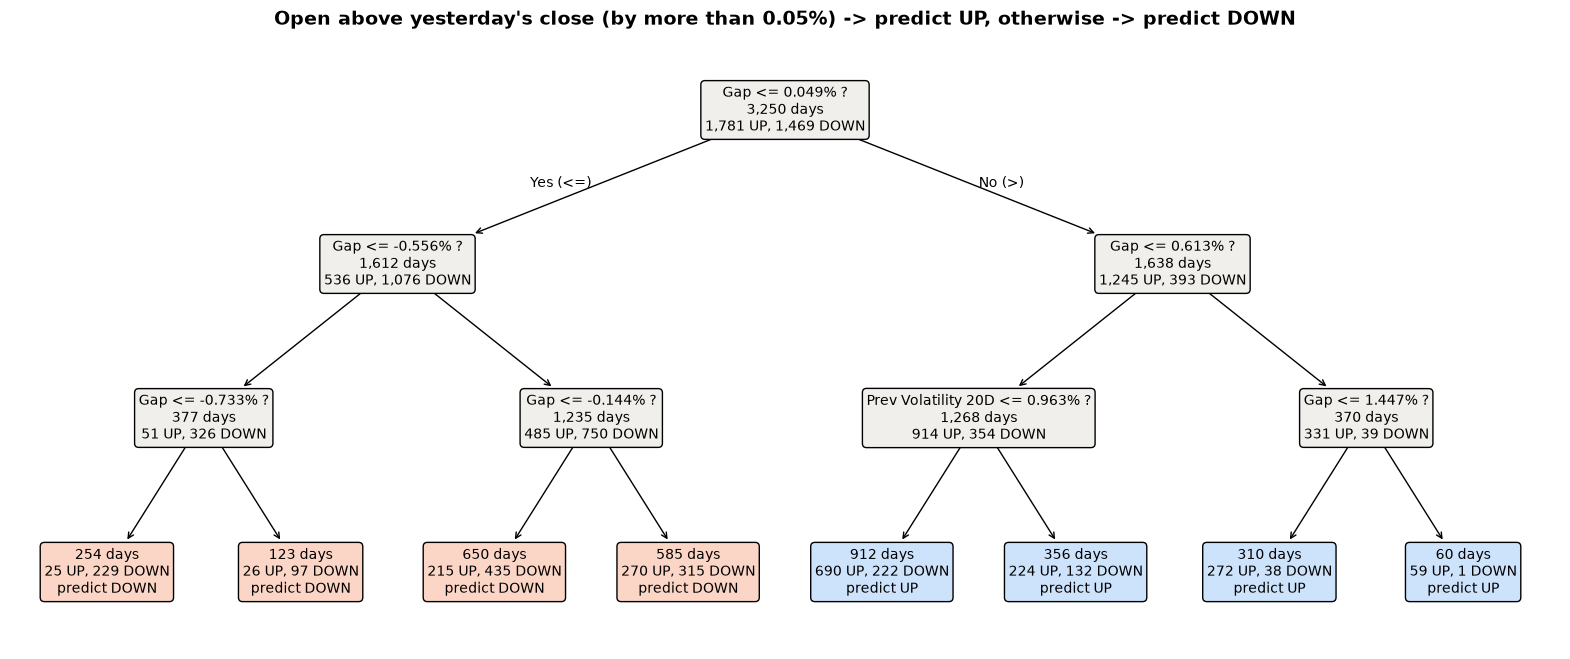

In [22]:
# draw the tree; relabel() only rewrites sklearn's box text in plain words
def relabel(text):
    is_question = "<=" in text
    out = []
    for line in text.split("\n"):
        m = re.match(r"(.+) <= (-?[\d.]+)$", line)
        if m:
            name, value = m.group(1), float(m.group(2))
            shown = f"{value:.3f}" if name == "Prev Volume Ratio" else f"{value:.3%}"
            out.append(f"{name} <= {shown} ?")
        elif line.startswith("samples"):
            out.append(f"{int(line.split('= ')[1]):,} days")
        elif line.startswith("value"):
            down_n, up_n = [int(float(v)) for v in re.findall(r"[\d.]+", line)]
            out.append(f"{up_n:,} UP, {down_n:,} DOWN")
        elif line.startswith("class") and not is_question:
            out.append("predict " + line.split("= ")[1])
    return "\n".join(out)

fig, ax = plt.subplots(figsize=(20, 8))
boxes = plot_tree(tree, feature_names=FEATURES, class_names=["DOWN", "UP"], impurity=False,
                  precision=6, rounded=True, fontsize=10, ax=ax)
for box in boxes:
    text = box.get_text()
    if box.get_bbox_patch() is None:                 # the small True/False labels on the first arrows
        box.set_text("Yes (<=)" if text.strip() == "True" else "No (>)")
        continue
    color = "#f0efec" if "<=" in text else ("#cde2fb" if "class = UP" in text else "#fbd5c5")
    box.get_bbox_patch().set_facecolor(color)
    box.set_text(relabel(text))
ax.set_title("Open above yesterday's close (by more than 0.05%) -> predict UP, otherwise -> predict DOWN",
             fontsize=14, fontweight="bold", loc="center")
save(fig, "open_gap_decision_tree.png")
plt.show()

### 8.4 The leaves (Excel: Leaves tab)

Each leaf predicts what most of its training days did. The last columns show how the same leaves did on the 2023 and
2024–2025 days.

In [23]:
# days and share of UP days in each leaf, for training, 2023 and 2024-2025
def leaf_table(part, name):
    return part.assign(leaf=tree.apply(part[FEATURES])).groupby("leaf")[TARGET].agg(**{f"{name} days": "count", f"{name} % UP": "mean"})

leaves = leaf_table(train, "Train").join(leaf_table(valid, "2023")).join(leaf_table(test, "2024-25"))
leaves["2023 days"] = leaves["2023 days"].fillna(0).astype(int)      # leaf 8 had no days in 2023
leaves.insert(0, "Leaf", range(1, len(leaves) + 1))
leaves.insert(1, "Predict", np.where(leaves["Train % UP"] > 0.5, "UP", "DOWN"))
for col in ["Train % UP", "2023 % UP", "2024-25 % UP"]:
    leaves[col] = (leaves[col] * 100).round(1)
leaves.set_index("Leaf")

,Predict,Train days,Train % UP,2023 days,2023 % UP,2024-25 days,2024-25 % UP
Leaf,,,,,,,
1,DOWN,254,9.8,12,16.7,38,15.8
2,DOWN,123,21.1,12,33.3,14,14.3
3,DOWN,650,33.1,63,28.6,81,43.2
4,DOWN,585,46.2,41,68.3,96,47.9
5,UP,912,75.7,75,66.7,188,71.3
6,UP,356,62.9,20,70.0,34,70.6
7,UP,310,87.7,27,88.9,44,88.6
8,UP,60,98.3,0,NaN,7,71.4


The 4 leaves on the left (gap down or flat) all predict DOWN and the 4 on the right (gap up) all predict UP. The share of
UP days goes from about 10% after a big gap down (leaf 1) to 98% after a big gap up (leaf 8), so the leaves also show
how sure the tree is. Most leaves look similar in all three periods. The weak one is leaf 4 (gap between −0.14% and
+0.05%), which is close to 50% and went over it in 2023.

## 9. Results

The tree was trained on 2010–2022 and checked on 2023. Then the same tree, without any changes, was run once on the
test years 2024–2025. We did not retrain it on 2023, so the test numbers are for exactly the tree shown above (and the
Excel workbook gives the same numbers on its Test Evaluate tab).

### 9.1 Confusion matrices

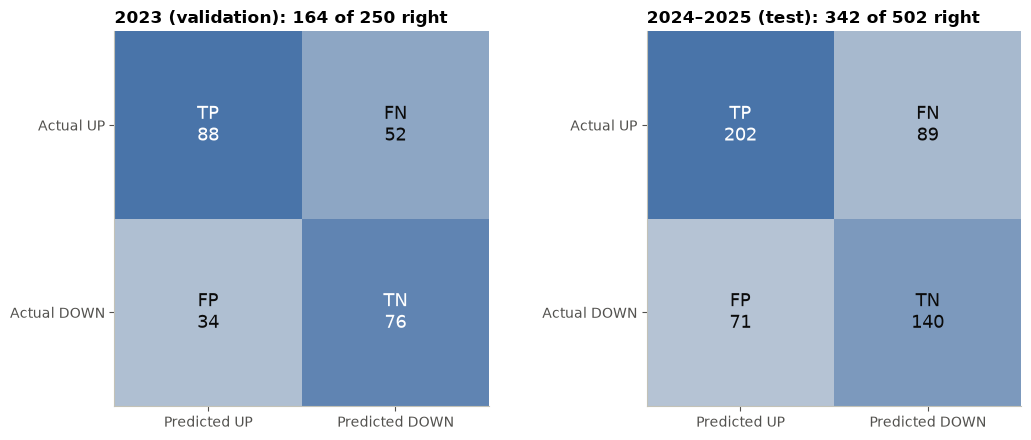

In [24]:
# predictions for 2023 and 2024-2025
pred_valid = tree.predict(valid[FEATURES])
pred_test = tree.predict(test[FEATURES])

# confusion matrix for each period (rows = actual, columns = predicted)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
blues = LinearSegmentedColormap.from_list("blues", ["#f0efec", "#184f95"])
for ax, (name, part, pred) in zip(axes, [("2023 (validation)", valid, pred_valid), ("2024–2025 (test)", test, pred_test)]):
    tn, fp, fn, tp = confusion_matrix(part[TARGET], pred).ravel()
    matrix = np.array([[tp, fn], [fp, tn]])
    ax.imshow(matrix, cmap=blues, vmin=0, vmax=matrix.max() * 1.3)
    for i, label_row in enumerate([["TP", "FN"], ["FP", "TN"]]):
        for j, label in enumerate(label_row):
            ax.text(j, i, f"{label}\n{matrix[i, j]}", ha="center", va="center", fontsize=13,
                    color="white" if matrix[i, j] > matrix.max() * 0.7 else INK)
    ax.set_xticks([0, 1], ["Predicted UP", "Predicted DOWN"])
    ax.set_yticks([0, 1], ["Actual UP", "Actual DOWN"])
    ax.grid(False)
    ax.set_title(f"{name}: {tp + tn} of {len(part)} right")
fig.tight_layout()
save(fig, "open_gap_confusion_matrices.png")
plt.show()

### 9.2 Metrics

In [25]:
# the class metrics, for the tree and for always guessing UP
def scores(actual, predicted):
    tn, fp, fn, tp = confusion_matrix(actual, predicted, labels=[0, 1]).ravel()
    return {"Accuracy": (tp + tn) / len(actual),
            "TPR (recall)": tp / (tp + fn),
            "FPR": fp / (fp + tn),
            "FNR": fn / (tp + fn),
            "Precision": tp / (tp + fp),
            "F1 score": 2 * tp / (2 * tp + fp + fn),
            "Balanced accuracy": (tp / (tp + fn) + tn / (tn + fp)) / 2}

always_up = lambda part: np.ones(len(part), dtype=int)
metrics = pd.DataFrame({
    "Tree 2023": scores(valid[TARGET], pred_valid),
    "Always UP 2023": scores(valid[TARGET], always_up(valid)),
    "Tree 2024-25": scores(test[TARGET], pred_test),
    "Always UP 2024-25": scores(test[TARGET], always_up(test)),
})
print(f"Training accuracy: {tree.score(train[FEATURES], train[TARGET]):.1%}")
(metrics * 100).round(1)

Training accuracy: 71.4%


,Tree 2023,Always UP 2023,Tree 2024-25,Always UP 2024-25
Accuracy,65.6,56.0,68.1,58.0
TPR (recall),62.9,100.0,69.4,100.0
FPR,30.9,100.0,33.6,100.0
FNR,37.1,0.0,30.6,0.0
Precision,72.1,56.0,74.0,58.0
F1 score,67.2,71.8,71.6,73.4
Balanced accuracy,66.0,50.0,67.9,50.0


| | 2023 (validation) | 2024–2025 (test) |
|---|---|---|
| Tree accuracy | 65.6% | 68.1% |
| Always UP | 56.0% | 58.0% |
| Difference | +9.6 points | +10.2 points |

The tree beats always-UP in both periods, and the test result is as good as the validation result. Training accuracy is
71.4%, only a few points higher, so the tree is not memorising the training years.

When the tree says UP it is right 72% (2023) and 74% (test) of the time. Balanced accuracy is 66% and 68% against
50% for always-UP.

F1 is the one metric where always-UP looks better (72% vs 67% in 2023, 73% vs 72% in the test). That is because F1 only
looks at the UP days, and a model that always says UP never misses one. Balanced accuracy counts UP and DOWN days
equally, and there the tree is clearly better.

### 9.3 Year by year

In [26]:
# accuracy of the tree and of always-UP in each year it never trained on
rows = []
for yr in [2023, 2024, 2025]:
    part = usable[usable["Date"].dt.year == yr]
    rows.append({"Year": yr, "Days": len(part),
                 "Tree": (tree.predict(part[FEATURES]) == part[TARGET]).mean() * 100,
                 "Always UP": part[TARGET].mean() * 100})
pd.DataFrame(rows).set_index("Year").round(1)

,Days,Tree,Always UP
Year,,,
2023,250,65.6,56.0
2024,252,71.8,58.7
2025,250,64.4,57.2


The tree is ahead of always-UP in each year: 2023 (65.6% vs 56.0%), 2024 (71.8% vs 58.7%) and 2025 (64.4% vs 57.2%).

## 10. Extra Checks

### 10.1 Overfitting: what if the tree had more questions?

Here we grow trees with 1 to 10 questions and no limit on leaf size, and compare training accuracy with 2023 accuracy.
This is only a check. The settings in 8.2 were chosen before, as in class, and were not changed after this.

No limits: 33 questions deep, 695 leaves, training 100.0%, 2023 57.6%


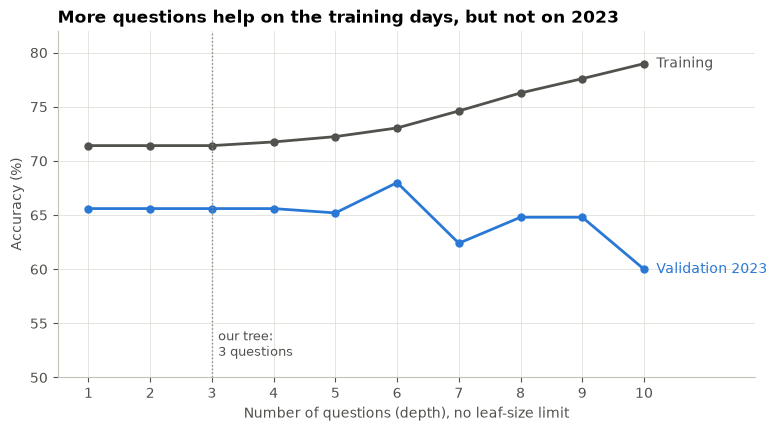

In [27]:
# training vs 2023 accuracy for deeper and deeper trees
rows = []
for depth in range(1, 11):
    t = DecisionTreeClassifier(criterion="entropy", max_depth=depth, random_state=0).fit(train[FEATURES], train[TARGET])
    rows.append({"Depth": depth, "Training": t.score(train[FEATURES], train[TARGET]) * 100,
                 "Validation 2023": t.score(valid[FEATURES], valid[TARGET]) * 100})
depth_curve = pd.DataFrame(rows).set_index("Depth")

# a tree with no limits at all
full = DecisionTreeClassifier(criterion="entropy", random_state=0).fit(train[FEATURES], train[TARGET])
print(f"No limits: {full.get_depth()} questions deep, {full.get_n_leaves()} leaves, "
      f"training {full.score(train[FEATURES], train[TARGET]):.1%}, 2023 {full.score(valid[FEATURES], valid[TARGET]):.1%}")

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(depth_curve.index, depth_curve["Training"], color=DARK, lw=2, marker="o", ms=5)
ax.plot(depth_curve.index, depth_curve["Validation 2023"], color=UP_COLOR, lw=2, marker="o", ms=5)
ax.text(10.2, depth_curve["Training"].iloc[-1], "Training", va="center", color=DARK)
ax.text(10.2, depth_curve["Validation 2023"].iloc[-1], "Validation 2023", va="center", color=UP_COLOR)
ax.axvline(3, color=GREY, ls=":", lw=1)
ax.text(3.1, 52, "our tree:\n3 questions", color=DARK, fontsize=9)
ax.set_xticks(range(1, 11))
ax.set_xlim(0.5, 11.8)
ax.set_ylim(50, 82)
ax.set_xlabel("Number of questions (depth), no leaf-size limit")
ax.set_ylabel("Accuracy (%)")
ax.set_title("More questions help on the training days, but not on 2023")
save(fig, "open_gap_overfitting.png")
plt.show()

Training accuracy keeps going up with more questions (71% at depth 3, 79% at depth 10, and 100% with no limits), but
2023 accuracy does not follow: it moves between 60% and 68%, and the tree with no limits gets only 57.6%. The extra
questions are learning noise from the training years. This is why we keep the tree small.

### 10.2 Would other settings be better?

We picked 3 questions and at least 50 days per leaf before training. Here we try other numbers for both and score each
tree on 2023. This is only a check; we did not switch settings after it.

In [28]:
# try other settings: number of questions (depth) and smallest leaf size
rows = []
for depth in [1, 2, 3, 4, 5, 6, None]:          # None = no limit
    for leaf in [1, 25, 50, 100, 200]:
        t = DecisionTreeClassifier(criterion="entropy", max_depth=depth, min_samples_leaf=leaf, random_state=0)
        t.fit(train[FEATURES], train[TARGET])
        rows.append({"Questions": "no limit" if depth is None else str(depth),
                     "Min days per leaf": leaf,
                     "Leaves": t.get_n_leaves(),
                     "Validation 2023": t.score(valid[FEATURES], valid[TARGET]) * 100,
                     "Test 2024-25": t.score(test[FEATURES], test[TARGET]) * 100})
settings = pd.DataFrame(rows)

# 2023 accuracy (%) for every combination: rows = questions, columns = min days per leaf
settings.pivot(index="Questions", columns="Min days per leaf", values="Validation 2023").round(1)

Min days per leaf,1,25,50,100,200
Questions,,,,,
1,65.6,65.6,65.6,65.6,65.6
2,65.6,65.6,65.6,65.6,65.6
3,65.6,65.6,65.6,65.6,65.6
4,65.6,65.6,65.6,65.6,65.6
5,65.2,64.8,66.8,67.6,65.6
6,68.0,65.6,66.0,66.8,65.6
no limit,57.6,65.2,65.6,66.8,65.6


In [29]:
# our tree next to the tree that scored best on 2023
ours = settings[(settings["Questions"] == "3") & (settings["Min days per leaf"] == 50)].iloc[0]
best = settings.sort_values("Validation 2023", ascending=False).iloc[0]
pd.DataFrame([ours, best], index=["Our tree", "Best on 2023"]).round(1)

,Questions,Min days per leaf,Leaves,Validation 2023,Test 2024-25
Our tree,3,50,8,65.6,68.1
Best on 2023,6,1,49,68.0,66.9


Every tree with 1, 2 or 3 questions gets 65.6% on 2023, whatever the leaf size, because the gap question does all the
work. The best score on 2023 is 68.0%, from a tree with 6 questions and 49 leaves. That is only 6 more correct days out
of 250, and the same tree does worse than ours on 2024-25 (66.9% against 68.1%). Without limits the tree drops to 57.6%.
So no other setting is clearly better, and ours is the simplest, which is why we kept it.

### 10.3 Is the tree the same as one question?

All the left leaves say DOWN and all the right leaves say UP, so the tree should give the same answers as the single
rule "if the gap is above 0.0494%, predict UP".

In [30]:
# compare the tree with the one-question rule on every 2023-2025 day
first_cut = tree.tree_.threshold[0]
unseen = usable[usable["Set"] != "Train"]
rule = (unseen["Gap"] > first_cut).astype(int)
print(f"First cut-off: {first_cut:.4%}")
print("Days where the rule and the tree disagree:", (rule != tree.predict(unseen[FEATURES])).sum(), "of", len(unseen))

First cut-off: 0.0494%
Days where the rule and the tree disagree: 0 of 752


They agree on every day. So if we pruned questions 2 and 3, the predictions would not change. We still show the full
tree because the leaves tell us how confident each answer is.

### 10.4 Where does the tree get it wrong?

We group all the days the tree never trained on (2023–2025) by the size of the gap.

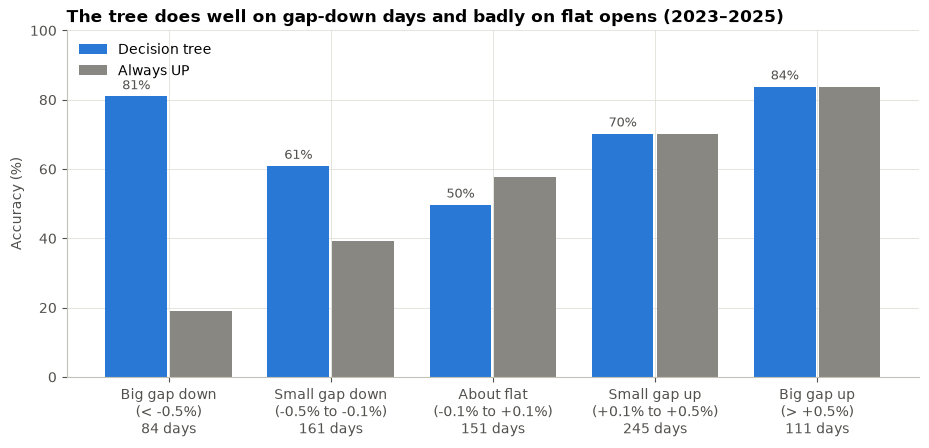

In [31]:
# accuracy of the tree and of always-UP for each gap size, on 2023-2025
gap_bins = [-np.inf, -0.005, -0.001, 0.001, 0.005, np.inf]
gap_names = ["Big gap down\n(< -0.5%)", "Small gap down\n(-0.5% to -0.1%)", "About flat\n(-0.1% to +0.1%)",
             "Small gap up\n(+0.1% to +0.5%)", "Big gap up\n(> +0.5%)"]
right = tree.predict(unseen[FEATURES]) == unseen[TARGET]
errors = (unseen.assign(group=pd.cut(unseen["Gap"], bins=gap_bins, labels=gap_names), right=right)
                .groupby("group", observed=True)
                .agg(days=("right", "size"), tree=("right", "mean"), always_up=(TARGET, "mean")))

x = np.arange(len(errors))
fig, ax = plt.subplots(figsize=(11, 4.5))
b1 = ax.bar(x - 0.2, errors["tree"] * 100, width=0.38, color=UP_COLOR, label="Decision tree")
ax.bar(x + 0.2, errors["always_up"] * 100, width=0.38, color=GREY, label="Always UP")
ax.bar_label(b1, labels=[f"{v:.0%}" for v in errors["tree"]], padding=3, color=DARK, fontsize=9)
ax.set_xticks(x, [f"{name}\n{n} days" for name, n in zip(errors.index, errors["days"])])
ax.set_ylim(0, 100)
ax.set_ylabel("Accuracy (%)")
ax.legend(loc="upper left", frameon=False)
ax.set_title("The tree does well on gap-down days and badly on flat opens (2023–2025)")
save(fig, "open_gap_errors_by_gap.png")
plt.show()

The tree is strongest on gap-down days: 81% right after a big gap down and 61% after a small one, where always-UP gets
only 19% and 39%. On gap-up days it says UP, the same as always-UP, so both score the same. The weak spot is a flat
open (between −0.1% and +0.1%): the tree is right only about half the time there, because a flat open tells us very
little about the rest of the day.

## 11. Save Output Files

In [32]:
# save the modified data, the predictions, the metrics and the outlier check as csv files
predictions = unseen[["Date", "Set", "Open", "Prev Close", "Gap", TARGET]].assign(
    Leaf=tree.apply(unseen[FEATURES]), Prediction=tree.predict(unseen[FEATURES]))
files = {
    "open_gap_modeling_data.csv": usable,
    "open_gap_predictions_2023_2025.csv": predictions,
    "open_gap_metrics.csv": metrics.rename_axis("Metric").reset_index(),
    "open_gap_outlier_summary.csv": outlier_summary,
}
for name, table in files.items():
    table.to_csv(OUTPUT_DIR / name, index=False)
    print("Saved", OUTPUT_DIR / name, f"({len(table):,} rows)")

Saved outputs\open_gap_modeling_data.csv (4,002 rows)
Saved outputs\open_gap_predictions_2023_2025.csv (752 rows)
Saved outputs\open_gap_metrics.csv (7 rows)
Saved outputs\open_gap_outlier_summary.csv (4 rows)


The charts are saved in the same `outputs` folder as PNG files.

## 12. Conclusion

The data was clean apart from one missing trading day (17 Feb 2011), which does not change the tree. The extreme values
were real market events, so we kept them.

The tree only needs one thing to make its decision: the opening gap. In simple words:

> If SPY opens more than 0.05% above yesterday's close, predict UP. Otherwise predict DOWN.

It was right on 65.6% of the 2023 days and 68.1% of the 2024–2025 test days, compared to 56.0% and 58.0% for always
guessing UP. It also beat always-UP in each of the three years separately. So the direction SPY opens in usually holds
until the close, about 2 days out of 3.

**Limitations**

- It is not a forecast of tomorrow. The gap has already happened at 9:30, so part of the day's move is already known.
- Flat opens are hard to call (about 50% right).
- We only used SPY's own prices and volume. News, interest rates and other markets are not in the data.
- Yesterday's return, range, volatility and volume added almost nothing. Other features could be tried in the future.